# Etapa 4b · Investigação: por que a rede perde em intenção

| | |
|---|---|
| **Pergunta** | Por que a rede do zero perde para o saco de palavras em intenção, e dá para recuperar sem perder as entidades? |
| **Entrada** | `entregas/04_treino/` (modelos e previsões da Etapa 4) e `entregas/02_avaliacao/` (linha de base). |
| **Entrega** | `entregas/04b_intencao/`: o diagnóstico, a comparação das candidatas e a decisão sobre a configuração do modelo que segue para as próximas etapas. |
| **Pronto quando** | (1) o diagnóstico separa as hipóteses com medidas; (2) cada candidata tem 3 sementes; (3) a decisão sai de `dev`, pela regra escrita antes do resultado; (4) a configuração que segue adiante está gravada e, se mudou, foi medida no teste. |

**Por que agora.** A Etapa 4 mostrou que a rede ganha com folga em entidades e exact match, mas fica abaixo da linha de base em acurácia de intenção. Destilação, poda e quantização partem todas desta arquitetura; este é o último momento barato para mexer nela.

**Artigos de apoio**

- Caminho linear ao lado do profundo: Cheng et al., *Wide & Deep Learning for Recommender Systems* ([arXiv 1606.07792](https://arxiv.org/abs/1606.07792)).
- Média dos pesos: Izmailov et al., *Averaging Weights Leads to Wider Optima and Better Generalization* ([arXiv 1803.05407](https://arxiv.org/abs/1803.05407)).
- Suavização de rótulos: Szegedy et al., *Rethinking the Inception Architecture* ([arXiv 1512.00567](https://arxiv.org/abs/1512.00567)); Müller et al., *When Does Label Smoothing Help?* ([arXiv 1906.02629](https://arxiv.org/abs/1906.02629)).
- Variação entre sementes: Reimers & Gurevych ([arXiv 1707.09861](https://arxiv.org/abs/1707.09861)).

**Roteiro**

1. O problema
2. Diagnóstico
3. As candidatas e a regra
4. Resultados em `dev`
5. Decisão
6. A configuração que segue adiante
7. Entrega
8. Resposta

In [1]:
import json
import shutil
from collections import Counter
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union

from especialista import visual
from especialista.avaliacao import eficiencia, qualidade, resultados
from especialista.avaliacao.previsao import carregar_previsoes, ouro, salvar_previsoes
from especialista.caminhos import ENTREGAS, RAIZ, entrega
from especialista.dados import massive
from especialista.experimentos import etapa4b
from especialista.modelos.diet import Config, SistemaDiet
from especialista.modelos.diet.features import features_do_texto

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 160)
torch.set_num_threads(1)

PASTA = entrega("04b_intencao")
SEMENTES = etapa4b.SEMENTES
ETAPA4 = ENTREGAS / "04_treino"

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
ouro_dev, ouro_teste = ouro(dev), ouro(teste)

_, base_dev = carregar_previsoes(ENTREGAS / "02_avaliacao" / "previsoes" / "linha_de_base_dev.parquet")
_, base_teste = carregar_previsoes(ENTREGAS / "02_avaliacao" / "previsoes" / "linha_de_base_test.parquet")
controle_dev = [carregar_previsoes(ETAPA4 / "previsoes" / f"semente_{s}_dev.parquet")[1] for s in SEMENTES]
controle_teste = [carregar_previsoes(ETAPA4 / "previsoes" / f"semente_{s}_test.parquet")[1] for s in SEMENTES]


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x):
    return f"{100 * x:+.1f}".replace(".", ",").replace("-", "−")


def com_intervalo(linha):
    return f"{dif(linha['diferenca'])} ({dif(linha['ic_min'])} a {dif(linha['ic_max'])})"

## 1. O problema

O ponto de partida, medido na Etapa 4 (em `dev`, média de 3 sementes):

In [2]:
contra_base = qualidade.comparar_grupos(ouro_dev, [base_dev], controle_dev)
pd.DataFrame({
    "linha de base": contra_base["a"].map(pts),
    "rede do zero": contra_base["b"].map(pts),
    "diferença (intervalo de 95%)": [com_intervalo(l) for _, l in contra_base.iterrows()],
}).loc[list(qualidade.METRICAS)].rename(index=qualidade.NOMES)

,linha de base,rede do zero,diferença (intervalo de 95%)
Acurácia de intenção,"84,5","82,8","−1,7 (−2,8 a −0,6)"
Macro-F1 de intenção,"82,0","80,3","−1,7 (−3,7 a +0,3)"
F1 de entidades,"49,9","74,3","+24,4 (+22,4 a +26,5)"
Exact match,"45,1","60,9","+15,8 (+14,1 a +17,8)"


A rede perde em intenção e ganha em todo o resto. Antes de mexer na rede, é preciso saber **por que** ela perde: cada causa possível pede um remédio diferente.

## 2. Diagnóstico

### 2.1 Os dois sistemas erram nos mesmos enunciados?

Se a linha de base acertasse tudo o que a rede acerta e mais um pouco, a rede simplesmente saberia menos. Se cada uma acerta coisas que a outra erra, há informação complementar.

In [3]:
certo = np.array([o.intent for o in ouro_dev])
da_base = np.array([p.intent for p in base_dev])
das_redes = [np.array([p.intent for p in previsoes]) for previsoes in controle_dev]

acordo = pd.Series({
    "As duas acertam": np.mean([((da_base == certo) & (r == certo)).mean() for r in das_redes]),
    "Só a linha de base acerta": np.mean([((da_base == certo) & (r != certo)).mean() for r in das_redes]),
    "Só a rede acerta": np.mean([((da_base != certo) & (r == certo)).mean() for r in das_redes]),
    "As duas erram": np.mean([((da_base != certo) & (r != certo)).mean() for r in das_redes]),
})
teto_da_uniao = acordo.iloc[:3].sum()
acordo.map(lambda v: pts(v) + "%").rename("parte de dev (média de 3 sementes)").to_frame()

,parte de dev (média de 3 sementes)
As duas acertam,"78,6%"
Só a linha de base acerta,"5,9%"
Só a rede acerta,"4,2%"
As duas erram,"11,3%"


### 2.2 A rede varia de um treino para outro?

Três redes idênticas, treinadas com sementes diferentes, deveriam responder quase igual. Duas medidas: em quantos enunciados duas sementes dão a mesma intenção, e o que acontece quando as três votam.

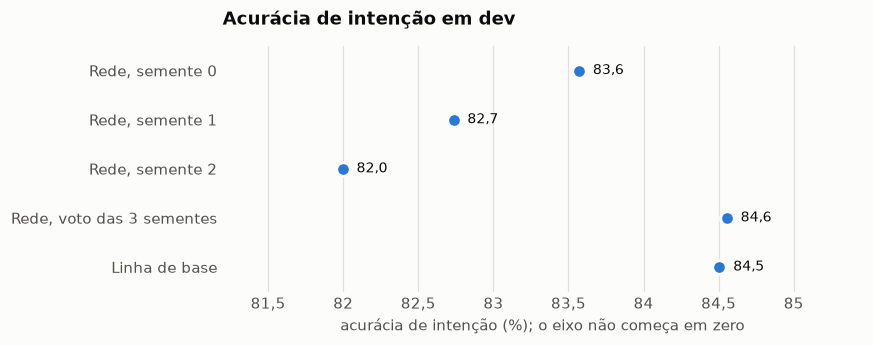

Duas sementes dão a mesma intenção em 85,6% dos enunciados de dev.
Acurácia de intenção da semente 0: 99,2% no treino, 83,6% em dev.


In [4]:
concordancia = np.mean([(das_redes[i] == das_redes[j]).mean() for i, j in ((0, 1), (0, 2), (1, 2))])
voto = np.array([Counter(respostas).most_common(1)[0][0] for respostas in zip(*das_redes)])
acerto_do_voto = (voto == certo).mean()
acerto_das_redes = [(r == certo).mean() for r in das_redes]
acerto_da_base = (da_base == certo).mean()

modelo_0 = SistemaDiet.carregar(ETAPA4 / "modelos" / "semente_0", "cuda" if torch.cuda.is_available() else "cpu")
no_treino = np.mean([p.intent == i for p, i in zip(modelo_0.prever(list(treino["utt"])), treino["intent"])])

pontos = {
    **{f"Rede, semente {s}": a for s, a in zip(SEMENTES, acerto_das_redes)},
    "Rede, voto das 3 sementes": acerto_do_voto,
    "Linha de base": acerto_da_base,
}
fig, ax = plt.subplots(figsize=(7.5, 2.9))
for y, (nome, valor) in enumerate(pontos.items()):
    ax.plot(100 * valor, y, "o", color=visual.AZUL, markersize=9, markeredgecolor=visual.SUPERFICIE, markeredgewidth=2)
    ax.annotate(pts(valor), (100 * valor, y), xytext=(9, 0), textcoords="offset points", va="center", fontsize=9, color=visual.TINTA)
ax.set_yticks(range(len(pontos)), list(pontos))
ax.set_ylim(len(pontos) - 0.5, -0.5)
ax.set_xlim(100 * min(pontos.values()) - 0.8, 100 * max(pontos.values()) + 0.9)
ax.xaxis.grid(True)
ax.xaxis.set_major_formatter(visual.VIRGULA)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.set_title("Acurácia de intenção em dev")
ax.set_xlabel("acurácia de intenção (%); o eixo não começa em zero")
visual.salvar(fig, PASTA, "variancia")
plt.show()

print(f"Duas sementes dão a mesma intenção em {pts(concordancia)}% dos enunciados de dev.")
print(f"Acurácia de intenção da semente 0: {pts(no_treino)}% no treino, {pts(acerto_das_redes[0])}% em dev.")

### 2.3 Em que classes a rede perde?

In [5]:
tamanho_da_classe = dev["intent"].map(treino["intent"].value_counts()).to_numpy()
visto = dev["utt_in_train"].to_numpy()
recortes = {
    "Intenções com menos de 100 exemplos de treino": tamanho_da_classe < 100,
    "Intenções com 100 a 299 exemplos": (tamanho_da_classe >= 100) & (tamanho_da_classe < 300),
    "Intenções com 300 exemplos ou mais": tamanho_da_classe >= 300,
    "Enunciados cujo texto está no treino": visto,
    "Enunciados inéditos": ~visto,
}
por_recorte = pd.DataFrame([
    {
        "recorte": nome,
        "enunciados": n(m.sum()),
        "linha de base": pts((da_base[m] == certo[m]).mean()),
        "rede (média de 3 sementes)": pts(np.mean([(r[m] == certo[m]).mean() for r in das_redes])),
        "diferença": dif(np.mean([(r[m] == certo[m]).mean() for r in das_redes]) - (da_base[m] == certo[m]).mean()),
    }
    for nome, m in recortes.items()
]).set_index("recorte")
por_recorte

,enunciados,linha de base,rede (média de 3 sementes),diferença
recorte,,,,
Intenções com menos de 100 exemplos de treino,155,"80,0","83,9","+3,9"
Intenções com 100 a 299 exemplos,872,"84,5","83,1","−1,4"
Intenções com 300 exemplos ou mais,1.006,"85,2","82,3","−2,9"
Enunciados cujo texto está no treino,143,"95,1","97,0","+1,9"
Enunciados inéditos,1.890,"83,7","81,7","−2,0"


### 2.4 A informação está nos features da rede?

A linha de base usa features um pouco diferentes dos da rede (inclui pares de palavras; pesa cada feature por TF-IDF). Para separar "a rede não recebe a informação" de "a rede recebe e não aproveita", treina-se o mesmo classificador linear da linha de base sobre **exatamente os features que a rede vê**.

In [6]:
vocabulario_da_rede = set(modelo_0.featurizador.vocabulario)
features_da_rede = lambda texto: [f for palavra in texto.split() for f in features_do_texto(palavra) if f in vocabulario_da_rede]
palavras = lambda pares: TfidfVectorizer(analyzer="word", token_pattern=r"\S+", ngram_range=(1, 2 if pares else 1), sublinear_tf=True)
caracteres = lambda: TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)

sondas = {
    "Linear sobre os features da rede, ligado/desligado": CountVectorizer(analyzer=features_da_rede, binary=True),
    "Linear sobre os features da rede, com peso TF-IDF": TfidfVectorizer(analyzer=features_da_rede, sublinear_tf=True),
    "Linha de base sem os pares de palavras": make_union(palavras(False), caracteres()),
    "Linha de base completa": make_union(palavras(True), caracteres()),
}
linhas = []
for nome, vetorizador in sondas.items():
    sonda = make_pipeline(vetorizador, LogisticRegression(C=10.0, max_iter=2000)).fit(treino["utt"], treino["intent"])
    linhas.append({"classificador linear": nome, "features": n(sonda[-1].coef_.shape[1]),
                   "acurácia de intenção em dev": (sonda.predict(dev["utt"]) == certo).mean()})
resultado_das_sondas = pd.DataFrame(linhas).set_index("classificador linear")
resultado_das_sondas.assign(**{"acurácia de intenção em dev": resultado_das_sondas["acurácia de intenção em dev"].map(pts)})

,features,acurácia de intenção em dev
classificador linear,,
"Linear sobre os features da rede, ligado/desligado",25.202,"81,6"
"Linear sobre os features da rede, com peso TF-IDF",25.202,"83,6"
Linha de base sem os pares de palavras,40.401,"84,0"
Linha de base completa,65.567,"84,5"


In [7]:
sonda_binaria, sonda_tfidf = resultado_das_sondas["acurácia de intenção em dev"].iloc[:2]
media_das_redes = float(np.mean(acerto_das_redes))
display(Markdown(f"""
**Leitura do diagnóstico.**

1. **Os erros são em boa parte diferentes.** A linha de base acerta {pts(acordo['Só a linha de base acerta'])}% dos enunciados que a rede erra, e a rede acerta {pts(acordo['Só a rede acerta'])}% que a linha de base erra. Se um sistema soubesse escolher sempre o que está certo, chegaria a {pts(teto_da_uniao)}%.
2. **A rede varia muito de um treino para outro.** Duas sementes só concordam em {pts(concordancia)}% dos enunciados. O voto das 3 sementes faz {pts(acerto_do_voto)}%, contra {pts(media_das_redes)}% da média delas e {pts(acerto_da_base)}% da linha de base. A rede acerta {pts(no_treino)}% da intenção no treino e {pts(acerto_das_redes[0])}% em `dev`: ela decora o treino.
3. **O sinal muda com o tamanho da classe.** Nas intenções com menos de 100 exemplos de treino a diferença da rede para a linha de base é de {por_recorte.iloc[0]['diferença']} pontos; nas de 300 ou mais, {por_recorte.iloc[2]['diferença']}. Nos enunciados inéditos, {por_recorte.iloc[4]['diferença']}.
4. **A informação está nos features.** Um classificador linear sobre os mesmos features da rede faz {pts(sonda_tfidf)}% com peso TF-IDF e {pts(sonda_binaria)}% sem ele. A rede ({pts(media_das_redes)}%) recebe o que precisa.

**O que isso muda.** A hipótese com que esta investigação começou era de acesso: a cabeça de intenção estaria longe demais dos features. O diagnóstico aponta mais para **variância**: a rede tem capacidade de sobra, decora o treino e cada semente decora de um jeito. As candidatas abaixo cobrem as duas explicações.
"""))


**Leitura do diagnóstico.**

1. **Os erros são em boa parte diferentes.** A linha de base acerta 5,9% dos enunciados que a rede erra, e a rede acerta 4,2% que a linha de base erra. Se um sistema soubesse escolher sempre o que está certo, chegaria a 88,7%.
2. **A rede varia muito de um treino para outro.** Duas sementes só concordam em 85,6% dos enunciados. O voto das 3 sementes faz 84,6%, contra 82,8% da média delas e 84,5% da linha de base. A rede acerta 99,2% da intenção no treino e 83,6% em `dev`: ela decora o treino.
3. **O sinal muda com o tamanho da classe.** Nas intenções com menos de 100 exemplos de treino a diferença da rede para a linha de base é de +3,9 pontos; nas de 300 ou mais, −2,9. Nos enunciados inéditos, −2,0.
4. **A informação está nos features.** Um classificador linear sobre os mesmos features da rede faz 83,6% com peso TF-IDF e 81,6% sem ele. A rede (82,8%) recebe o que precisa.

**O que isso muda.** A hipótese com que esta investigação começou era de acesso: a cabeça de intenção estaria longe demais dos features. O diagnóstico aponta mais para **variância**: a rede tem capacidade de sobra, decora o treino e cada semente decora de um jeito. As candidatas abaixo cobrem as duas explicações.


## 3. As candidatas e a regra

Cinco candidatas, cada uma mudando uma única coisa em relação à configuração da Etapa 4. Três testam a hipótese de acesso; duas, a de variância.

In [8]:
controle_parametros = modelo_0.parametros
for variante in etapa4b.VARIANTES:
    for semente in SEMENTES:
        etapa4b.executar(variante, semente)   # treina se ainda não existe
execucoes = {v: [etapa4b.carregar(v, s) for s in SEMENTES] for v in etapa4b.VARIANTES}
grupo_dev = {v: [e["previsoes_dev"] for e in es] for v, es in execucoes.items()}
parametros = {v: SistemaDiet.carregar(execucoes[v][0]["pasta"] / "modelo").parametros for v in etapa4b.VARIANTES}

pd.DataFrame([
    {
        "candidata": d["nome"],
        "hipótese que ela testa": d["hipotese"],
        "o que muda": ", ".join(f"{k} = {v}" for k, v in {**d["config"], **d["receita"]}.items()),
        "parâmetros a mais": n(parametros[v] - controle_parametros),
    }
    for v, d in etapa4b.VARIANTES.items()
]).set_index("candidata")

,hipótese que ela testa,o que muda,parâmetros a mais
candidata,,,
Atalho a partir do resumo (128 dimensões),O encoder e o espaço de 20 dimensões atrapalham a intenção,atalho_intencao = resumo,7.740
Atalho a partir dos features (classificador linear dentro da rede),"Falta um caminho linear sobre os n-gramas, como o da linha de base",atalho_intencao = features,1.512.120
Espaço de rótulos com 64 dimensões (o padrão é 20),O espaço de 20 dimensões é um gargalo para 60 intenções,d_rotulo = 64,30.932
"Média móvel dos pesos (fator 0,999)",Os pesos do último passo oscilam; a média dos passos recentes generaliza melhor,media_dos_pesos = 0.999,0
"Suavização de rótulos na intenção (0,1)",A rede fica confiante demais no treino; suavizar o alvo reduz o sobreajuste,suavizacao = 0.1,0


**As candidatas, em uma frase cada.**

- **Atalho a partir do resumo.** A pontuação de intenção ganha um termo linear calculado direto do resumo de 128 dimensões do enunciado, sem passar pelo encoder nem pelo espaço de 20 dimensões.
- **Atalho a partir dos features.** A pontuação ganha um peso por par (feature, intenção): é um classificador linear como o da linha de base, treinado dentro da rede e somado ao caminho profundo. É a ideia do *Wide & Deep*.
- **Espaço de rótulos de 64 dimensões.** Testa se as 20 dimensões do DIET apertam demais 60 intenções.
- **Média móvel dos pesos.** Em vez dos pesos do último passo, que oscilam, usa-se a média dos passos recentes. Não muda a rede nem o custo de usar o modelo.
- **Suavização de rótulos.** O alvo da intenção deixa de ser "100% na classe certa" e passa a ser 90%, com o resto distribuído. Desencoraja a confiança exagerada.

**A regra, escrita antes de olhar os resultados:**

1. Uma candidata é **aprovada** se, em `dev` e na média de 3 sementes, a acurácia de intenção melhorar com intervalo de 95% todo acima de zero **e** o exact match não piorar de forma distinguível.
2. Entre as aprovadas, fica a de maior exact match. Se outra aprovada não for distinguivelmente pior que ela em exact match e tiver menos parâmetros, fica a mais barata.
3. Se a média móvel dos pesos (que muda só o treino) e uma mudança na rede forem aprovadas, a combinação é treinada, e fica se não for distinguivelmente pior, em exact match, que a melhor das duas.
4. Se nenhuma for aprovada, a configuração da Etapa 4 segue como está, e o resultado negativo fica registrado.

## 4. Resultados em `dev`

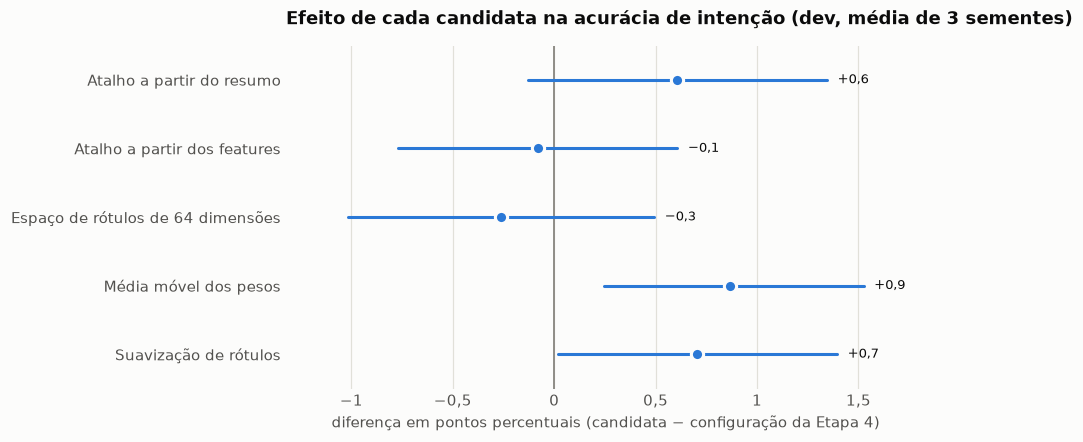

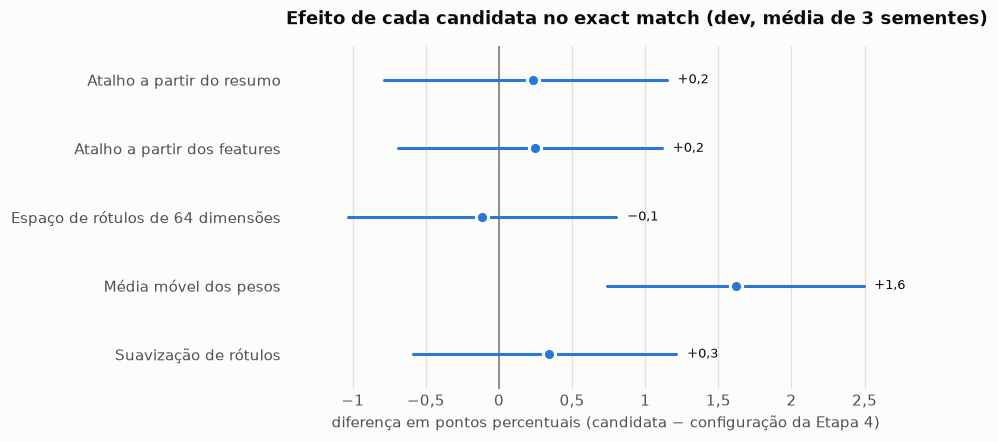

In [9]:
tabelas = {v: qualidade.comparar_grupos(ouro_dev, controle_dev, grupo_dev[v]) for v in etapa4b.VARIANTES}
nome = {v: d["nome"] for v, d in etapa4b.VARIANTES.items()}
curto = {
    "atalho_resumo": "Atalho a partir do resumo",
    "atalho_features": "Atalho a partir dos features",
    "rotulo_64": "Espaço de rótulos de 64 dimensões",
    "media_dos_pesos": "Média móvel dos pesos",
    "suavizacao": "Suavização de rótulos",
}

for metrica, titulo, arquivo in (
    ("intent_acc", "Efeito de cada candidata na acurácia de intenção (dev, média de 3 sementes)", "candidatas_intencao"),
    ("exact_match", "Efeito de cada candidata no exact match (dev, média de 3 sementes)", "candidatas_exact_match"),
):
    fig, ax = visual.diferencas_com_intervalo(
        {curto[v]: tuple(100 * tabelas[v].loc[metrica, c] for c in ("diferenca", "ic_min", "ic_max")) for v in tabelas},
        titulo, "diferença em pontos percentuais (candidata − configuração da Etapa 4)",
    )
    visual.salvar(fig, PASTA, arquivo)
    plt.show()

In [10]:
quadro = pd.DataFrame({
    curto[v]: {
        **{qualidade.NOMES[m]: f"{pts(tabelas[v].loc[m, 'b'])}  ({dif(tabelas[v].loc[m, 'diferenca'])}{' *' if tabelas[v].loc[m, 'distinguivel'] else ''})"
           for m in qualidade.METRICAS},
        "Desvio entre sementes (intenção)": pts(np.std([qualidade.avaliar(ouro_dev, p)["intent_acc"] for p in grupo_dev[v]], ddof=1)),
    }
    for v in tabelas
}).T
controle_linha = {qualidade.NOMES[m]: pts(tabelas["rotulo_64"].loc[m, "a"]) for m in qualidade.METRICAS}
controle_linha["Desvio entre sementes (intenção)"] = pts(np.std(acerto_das_redes, ddof=1))
quadro.loc["Configuração da Etapa 4 (controle)"] = controle_linha
print("Valor em dev (diferença para o controle).  * = intervalo de 95% não contém zero")
quadro

Valor em dev (diferença para o controle).  * = intervalo de 95% não contém zero


,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match,Desvio entre sementes (intenção)
Atalho a partir do resumo,"83,4 (+0,6)","81,1 (+0,8)","74,4 (+0,1)","61,1 (+0,2)","0,1"
Atalho a partir dos features,"82,7 (−0,1)","80,6 (+0,3)","74,2 (−0,1)","61,1 (+0,2)","0,3"
Espaço de rótulos de 64 dimensões,"82,5 (−0,3)","80,8 (+0,5)","74,7 (+0,4)","60,8 (−0,1)","1,0"
Média móvel dos pesos,"83,6 (+0,9 *)","81,8 (+1,5 *)","75,6 (+1,4 *)","62,5 (+1,6 *)","0,6"
Suavização de rótulos,"83,5 (+0,7 *)","81,7 (+1,4 *)","74,5 (+0,2)","61,2 (+0,3)","0,3"
Configuração da Etapa 4 (controle),"82,8","80,3","74,3","60,9","0,8"


## 5. Decisão

In [11]:
def aprovada(v):
    t = tabelas[v]
    return bool(t.loc["intent_acc", "ic_min"] > 0 and not t.loc["exact_match", "ic_max"] < 0)


aprovadas = [v for v in tabelas if aprovada(v)]


def escolher(candidatas):
    """Regra 2: a de maior exact match; se outra não for distinguivelmente pior e for mais barata, a mais barata."""
    melhor = max(candidatas, key=lambda v: tabelas[v].loc["exact_match", "b"])
    empatadas = [v for v in candidatas
                 if v == melhor or qualidade.comparar_grupos(ouro_dev, grupo_dev[melhor], grupo_dev[v]).loc["exact_match", "ic_max"] >= 0]
    return min(empatadas, key=lambda v: (parametros[v], -tabelas[v].loc["exact_match", "b"]))


na_rede = [v for v in aprovadas if v != "media_dos_pesos"]
adotada, definicao_final, grupo_final_dev, execucoes_finais = None, {"config": {}, "receita": {}}, controle_dev, None

if aprovadas:
    adotada = escolher(aprovadas)
    if "media_dos_pesos" in aprovadas and na_rede:
        # regra 3: testar a combinação da melhor mudança na rede com a média dos pesos
        da_rede = escolher(na_rede)
        combinada = {
            "nome": f"{curto[da_rede]} + média móvel dos pesos",
            "config": etapa4b.VARIANTES[da_rede]["config"],
            "receita": etapa4b.VARIANTES["media_dos_pesos"]["receita"],
        }
        for semente in SEMENTES:
            etapa4b.executar("combinada", semente, combinada)
        execucoes["combinada"] = [etapa4b.carregar("combinada", s) for s in SEMENTES]
        grupo_dev["combinada"] = [e["previsoes_dev"] for e in execucoes["combinada"]]
        tabelas["combinada"] = qualidade.comparar_grupos(ouro_dev, controle_dev, grupo_dev["combinada"])
        parametros["combinada"] = parametros[da_rede]
        curto["combinada"] = combinada["nome"]
        contra_a_melhor = qualidade.comparar_grupos(ouro_dev, grupo_dev[adotada], grupo_dev["combinada"])
        if not contra_a_melhor.loc["exact_match", "ic_max"] < 0:
            adotada = "combinada"
    definicao_final = combinada if adotada == "combinada" else etapa4b.VARIANTES[adotada]
    grupo_final_dev, execucoes_finais = grupo_dev[adotada], execucoes[adotada]

linhas = [{
    "candidata": curto[v],
    "intenção (intervalo de 95%)": com_intervalo(tabelas[v].loc["intent_acc"]),
    "exact match (intervalo de 95%)": com_intervalo(tabelas[v].loc["exact_match"]),
    "aprovada pela regra": "sim" if (v == "combinada" or aprovada(v)) else "não",
    "adotada": "sim" if v == adotada else "",
} for v in tabelas]
display(pd.DataFrame(linhas).set_index("candidata"))

de_acesso = ["atalho_resumo", "atalho_features", "rotulo_64"]
de_variancia = ["media_dos_pesos", "suavizacao"]
passaram = lambda grupo: f"{sum(v in aprovadas for v in grupo)} de {len(grupo)}"
por_um_fio = [v for v in aprovadas if tabelas[v].loc["intent_acc", "ic_min"] < 0.001]

display(Markdown(f"""
**Decisão.** {"Nenhuma candidata foi aprovada. A configuração da Etapa 4 segue como está." if adotada is None else f"Fica adotada: **{curto[adotada]}**."}

- **Hipótese de acesso** (atalhos e espaço de rótulos maior): passaram {passaram(de_acesso)} candidatas.
- **Hipótese de variância** (média dos pesos e suavização): passaram {passaram(de_variancia)} candidatas.
""" + ("".join(f"""
- **Aprovação por margem mínima:** "{curto[v]}" passou com limite inferior de +{num(100 * tabelas[v].loc['intent_acc', 'ic_min'], 2)} ponto em intenção. Com outra amostra de `dev` poderia não passar.""" for v in por_um_fio))))

if adotada == "combinada":
    print(f"Regra 3: a combinação contra a melhor candidata sozinha ({curto[escolher(aprovadas)]}), em dev")
    display(pd.DataFrame({
        "melhor sozinha": contra_a_melhor["a"].map(pts),
        "combinação": contra_a_melhor["b"].map(pts),
        "diferença (intervalo de 95%)": [com_intervalo(l) for _, l in contra_a_melhor.iterrows()],
    }).loc[list(qualidade.METRICAS)].rename(index=qualidade.NOMES))

,intenção (intervalo de 95%),exact match (intervalo de 95%),aprovada pela regra,adotada
candidata,,,,
Atalho a partir do resumo,"+0,6 (−0,1 a +1,3)","+0,2 (−0,8 a +1,1)",não,
Atalho a partir dos features,"−0,1 (−0,8 a +0,6)","+0,2 (−0,7 a +1,1)",não,
Espaço de rótulos de 64 dimensões,"−0,3 (−1,0 a +0,5)","−0,1 (−1,0 a +0,8)",não,
Média móvel dos pesos,"+0,9 (+0,2 a +1,5)","+1,6 (+0,7 a +2,5)",sim,
Suavização de rótulos,"+0,7 (+0,0 a +1,4)","+0,3 (−0,6 a +1,2)",sim,
Suavização de rótulos + média móvel dos pesos,"+1,2 (+0,5 a +1,9)","+1,7 (+0,8 a +2,7)",sim,sim



**Decisão.** Fica adotada: **Suavização de rótulos + média móvel dos pesos**.

- **Hipótese de acesso** (atalhos e espaço de rótulos maior): passaram 0 de 3 candidatas.
- **Hipótese de variância** (média dos pesos e suavização): passaram 2 de 2 candidatas.

- **Aprovação por margem mínima:** "Suavização de rótulos" passou com limite inferior de +0,02 ponto em intenção. Com outra amostra de `dev` poderia não passar.

Regra 3: a combinação contra a melhor candidata sozinha (Média móvel dos pesos), em dev


,melhor sozinha,combinação,diferença (intervalo de 95%)
Acurácia de intenção,"83,6","83,9","+0,3 (−0,3 a +1,0)"
Macro-F1 de intenção,"81,8","82,4","+0,6 (−0,4 a +1,8)"
F1 de entidades,"75,6","75,8","+0,1 (−0,5 a +0,7)"
Exact match,"62,5","62,6","+0,1 (−0,7 a +0,8)"


## 6. A configuração que segue adiante

Esta seção mede a configuração decidida acima. Se houve mudança, o teste é aberto para a nova configuração; a decisão já foi tomada em `dev`.

In [12]:
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
if adotada is None:
    pastas_dos_modelos = [ETAPA4 / "modelos" / f"semente_{s}" for s in SEMENTES]
    final_teste = controle_teste
else:
    pastas_dos_modelos = [e["pasta"] / "modelo" for e in execucoes_finais]
    final_teste = [SistemaDiet.carregar(p, dispositivo).prever(list(teste["utt"])) for p in pastas_dos_modelos]

na_cpu = SistemaDiet.carregar(pastas_dos_modelos[0], "cpu")
tempos = eficiencia.medir_latencia(na_cpu, list(dev["utt"]))
latencia = eficiencia.resumir_latencia(tempos)
# o modelo da Etapa 4, medido agora, na mesma sessão: latência só se compara assim
latencia_antes = eficiencia.resumir_latencia(eficiencia.medir_latencia(SistemaDiet.carregar(ETAPA4 / "modelos" / "semente_0", "cpu"), list(dev["utt"])))
bytes_modelo = sum(p.stat().st_size for p in pastas_dos_modelos[0].iterdir())

no_teste = qualidade.intervalo_do_grupo(ouro_teste, final_teste)
antes_teste = qualidade.intervalo_do_grupo(ouro_teste, controle_teste)
contra_antes = qualidade.comparar_grupos(ouro_teste, controle_teste, final_teste)
contra_base_teste = qualidade.comparar_grupos(ouro_teste, [base_teste], final_teste)

pd.DataFrame({
    "Etapa 4 (antes)": antes_teste["valor"].map(pts),
    "configuração que segue": [f"{pts(l['valor'])} ({pts(l['ic_min'])} a {pts(l['ic_max'])})" for _, l in no_teste.iterrows()],
    "diferença para a Etapa 4": [com_intervalo(l) if adotada else "igual" for _, l in contra_antes.iterrows()],
    "linha de base": contra_base_teste["a"].map(pts),
    "diferença para a linha de base": [com_intervalo(l) for _, l in contra_base_teste.iterrows()],
}).loc[list(qualidade.METRICAS)].rename(index=qualidade.NOMES)

,Etapa 4 (antes),configuração que segue,diferença para a Etapa 4,linha de base,diferença para a linha de base
Acurácia de intenção,"82,4","84,4 (83,2 a 85,6)","+2,0 (+1,4 a +2,6)","84,6","−0,2 (−1,1 a +0,8)"
Macro-F1 de intenção,"80,0","82,8 (81,0 a 84,8)","+2,8 (+1,5 a +4,0)","81,4","+1,4 (−0,6 a +3,4)"
F1 de entidades,"72,7","73,6 (72,2 a 75,1)","+0,9 (+0,3 a +1,6)","47,8","+25,9 (+24,0 a +27,6)"
Exact match,"60,3","62,5 (60,8 a 64,1)","+2,1 (+1,4 a +2,9)","45,2","+17,2 (+15,6 a +18,8)"


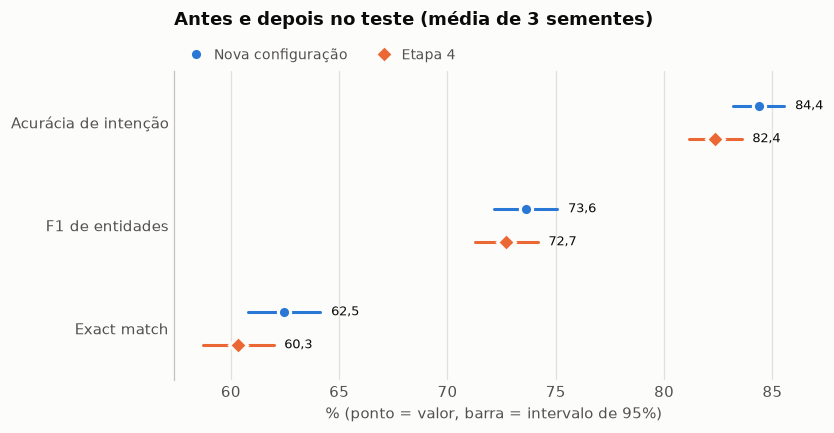

,configuração que segue
Parâmetros,4.895.834
Parâmetros a mais que na Etapa 4,0
Tamanho em disco (MB),"19,9"
"Latência p50 (ms), 1 núcleo de CPU","1,20"
Latência p95 (ms),"1,60"
"Latência p50 (ms) do modelo da Etapa 4, medida na mesma sessão","1,21"


In [13]:
if adotada is not None:
    tres = {"intent_acc": "Acurácia de intenção", "slot_f1": "F1 de entidades", "exact_match": "Exact match"}
    fig, ax = visual.pontos_com_intervalo(
        {
            "Nova configuração": {nome_m: tuple(100 * no_teste.loc[m, c] for c in ("valor", "ic_min", "ic_max")) for m, nome_m in tres.items()},
            "Etapa 4": {nome_m: tuple(100 * antes_teste.loc[m, c] for c in ("valor", "ic_min", "ic_max")) for m, nome_m in tres.items()},
        },
        "Antes e depois no teste (média de 3 sementes)", "% (ponto = valor, barra = intervalo de 95%)",
    )
    visual.salvar(fig, PASTA, "antes_e_depois_teste")
    plt.show()

pd.Series({
    "Parâmetros": n(na_cpu.parametros),
    "Parâmetros a mais que na Etapa 4": n(na_cpu.parametros - controle_parametros),
    "Tamanho em disco (MB)": num(bytes_modelo / 1e6),
    "Latência p50 (ms), 1 núcleo de CPU": num(latencia["latencia_p50_ms"], 2),
    "Latência p95 (ms)": num(latencia["latencia_p95_ms"], 2),
    "Latência p50 (ms) do modelo da Etapa 4, medida na mesma sessão": num(latencia_antes["latencia_p50_ms"], 2),
}).rename("configuração que segue").to_frame()

## 7. Entrega

A decisão fica gravada em `decisao.json`. É esse arquivo que as próximas etapas leem para saber com que configuração treinar os alunos e onde estão os modelos de referência.

In [14]:
nome_do_sistema = "DIET do zero (rótulos humanos)" if adotada is None else f"DIET do zero + {curto[adotada].lower()} (rótulos humanos)"
linhas_resultado = []
if adotada is not None:
    for i, semente in enumerate(SEMENTES):
        destino = PASTA / "modelos" / f"semente_{semente}"
        if destino.exists():
            shutil.rmtree(destino)
        shutil.copytree(pastas_dos_modelos[i], destino)
        salvar_previsoes(PASTA / "previsoes" / f"semente_{semente}_dev.parquet", dev["id"], grupo_final_dev[i])
        salvar_previsoes(PASTA / "previsoes" / f"semente_{semente}_test.parquet", teste["id"], final_teste[i])
    onde_estao_os_modelos = "entregas/04b_intencao/modelos"
else:
    onde_estao_os_modelos = "entregas/04_treino/modelos"

for particao, rotulos_humanos, grupo in (("dev", ouro_dev, grupo_final_dev), ("test", ouro_teste, final_teste)):
    linhas_resultado.append(resultados.registrar_grupo(
        f"{nome_do_sistema}, média de {len(SEMENTES)} sementes", particao, rotulos_humanos, grupo,
        tempos_ms=tempos, parametros=na_cpu.parametros, bytes_em_disco=bytes_modelo, threads=1,
    ))
resultados.salvar(linhas_resultado, PASTA)

pd.concat({curto[v]: t.loc[list(qualidade.METRICAS)] for v, t in tabelas.items()}, names=["candidata", "metrica"]).to_csv(PASTA / "candidatas.csv")

decisao = {
    "etapa": "04b_intencao",
    "gerado_em": date.today().isoformat(),
    "adotada": adotada,
    "nome": nome_do_sistema,
    "config": {**Config().como_dict(), **definicao_final["config"]},
    "receita": definicao_final["receita"],
    "mudou_em_relacao_a_etapa_4": {**definicao_final["config"], **definicao_final["receita"]},
    "modelos": onde_estao_os_modelos,
    "regra": "intenção melhora com IC95 acima de zero em dev (média de 3 sementes) e exact match não piora de forma distinguível",
    "aprovadas": aprovadas,
}
(PASTA / "decisao.json").write_text(json.dumps(decisao, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

relido = SistemaDiet.carregar(RAIZ / onde_estao_os_modelos / "semente_0", "cpu")
recarrega_ok = relido.prever(list(teste["utt"])) == final_teste[0]
print("Configuração que segue:", json.dumps(decisao["mudou_em_relacao_a_etapa_4"], ensure_ascii=False) or "{}", "| modelos em", onde_estao_os_modelos)
print("Modelo relido do disco reproduz as previsões do teste:", "sim" if recarrega_ok else "NÃO")

Configuração que segue: {"suavizacao": 0.1, "media_dos_pesos": 0.999} | modelos em entregas/04b_intencao/modelos
Modelo relido do disco reproduz as previsões do teste: sim


### Critério de pronto

In [15]:
pronto = pd.Series({
    "O diagnóstico separa as hipóteses com medidas": True,
    "Cada candidata tem 3 sementes": all(len(es) == 3 for es in execucoes.values()),
    "Decisão tomada em dev pela regra escrita antes": True,
    "Configuração que segue gravada e medida no teste": bool(recarrega_ok and (PASTA / "decisao.json").exists()),
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
O diagnóstico separa as hipóteses com medidas,sim
Cada candidata tem 3 sementes,sim
Decisão tomada em dev pela regra escrita antes,sim
Configuração que segue gravada e medida no teste,sim


## 8. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/04b_intencao/RESUMO.md`.

In [16]:
tabela_candidatas = "\n".join(
    f"| {curto[v]} | {com_intervalo(tabelas[v].loc['intent_acc'])} | {com_intervalo(tabelas[v].loc['exact_match'])} | {n(parametros[v] - controle_parametros)} | {'sim' if (v == 'combinada' or aprovada(v)) else 'não'} |"
    for v in tabelas
)
tabela_teste = "\n".join(
    f"| {qualidade.NOMES[m]} | {pts(antes_teste.loc[m, 'valor'])} | {pts(no_teste.loc[m, 'valor'])} ({pts(no_teste.loc[m, 'ic_min'])} a {pts(no_teste.loc[m, 'ic_max'])}) | {com_intervalo(contra_antes.loc[m]) if adotada else 'igual'} | {pts(contra_base_teste.loc[m, 'a'])} | {com_intervalo(contra_base_teste.loc[m])} |"
    for m in qualidade.METRICAS
)
intencao_base = contra_base_teste.loc["intent_acc"]
if intencao_base["ic_max"] < 0:
    situacao = f"A rede continua abaixo da linha de base em intenção no teste: {com_intervalo(intencao_base)}."
elif intencao_base["ic_min"] > 0:
    situacao = f"A rede passa a ficar acima da linha de base em intenção no teste: {com_intervalo(intencao_base)}."
else:
    situacao = f"No teste, a rede e a linha de base deixam de se distinguir em intenção: {com_intervalo(intencao_base)}."

hipoteses = (f"Das candidatas que davam à intenção mais acesso aos features ou mais espaço, passaram {passaram(de_acesso)}; "
             f"das que atacam a variância, {passaram(de_variancia)}.")
if adotada is None:
    resposta = "Nenhuma das cinco candidatas passou na regra. A configuração da Etapa 4 segue sem alteração para as próximas etapas."
else:
    mudanca = tabelas[adotada]
    resposta = (f"Fica adotada **{curto[adotada].lower()}**: em `dev`, {com_intervalo(mudanca.loc['intent_acc'])} pontos de acurácia de intenção "
                f"e {com_intervalo(mudanca.loc['exact_match'])} de exact match. No teste, a intenção vai de {pts(antes_teste.loc['intent_acc', 'valor'])} "
                f"para {pts(no_teste.loc['intent_acc', 'valor'])} e o exact match de {pts(antes_teste.loc['exact_match', 'valor'])} para {pts(no_teste.loc['exact_match', 'valor'])}, "
                + ("sem nenhum parâmetro a mais: a rede é a mesma na hora de usar." if parametros[adotada] == controle_parametros
                   else f"com {n(parametros[adotada] - controle_parametros)} parâmetros a mais."))

resumo = f"""# Etapa 4b · Investigação da intenção: resumo da entrega

**Pergunta.** Por que a rede do zero perde para o saco de palavras em intenção, e dá para recuperar sem perder as entidades?

**Resposta.** A rede perde por **variância**, não por falta de acesso aos features: ela acerta {pts(no_treino)}% da intenção no treino e {pts(acerto_das_redes[0])}% em `dev`, e duas sementes só concordam em {pts(concordancia)}% dos enunciados. {hipoteses} {resposta} {situacao}

## Diagnóstico (dev)

| Medida | Valor | O que diz |
|---|---|---|
| Só a linha de base acerta / só a rede acerta | {pts(acordo['Só a linha de base acerta'])}% / {pts(acordo['Só a rede acerta'])}% | Os erros são em boa parte diferentes |
| Acurácia de intenção no treino / em dev (semente 0) | {pts(no_treino)}% / {pts(acerto_das_redes[0])}% | A rede decora o treino |
| Concordância entre duas sementes | {pts(concordancia)}% | Cada treino decora de um jeito |
| Voto das 3 sementes / média das 3 / linha de base | {pts(acerto_do_voto)}% / {pts(media_das_redes)}% / {pts(acerto_da_base)}% | Tirar a variância já fecha a distância |
| Linear sobre os features da rede, com TF-IDF / sem | {pts(sonda_tfidf)}% / {pts(sonda_binaria)}% | A informação está nos features |

![Variância](figuras/variancia.png)

## Candidatas (dev, média de 3 sementes, diferença para a configuração da Etapa 4)

| Candidata | Intenção (intervalo de 95%) | Exact match (intervalo de 95%) | Parâmetros a mais | Aprovada |
|---|---|---|---|---|
{tabela_candidatas}

![Intenção](figuras/candidatas_intencao.png)

Regra: aprovada se a acurácia de intenção melhorar com intervalo de 95% todo acima de zero e o exact match não piorar de forma distinguível.

## A configuração que segue adiante (teste, média de 3 sementes)

| Métrica | Etapa 4 | Configuração que segue | Diferença para a Etapa 4 | Linha de base | Diferença para a linha de base |
|---|---|---|---|---|---|
{tabela_teste}

- Parâmetros: {n(na_cpu.parametros)} ({n(na_cpu.parametros - controle_parametros)} a mais que na Etapa 4).
- Latência: {num(latencia['latencia_p50_ms'], 2)} ms (p50) em 1 núcleo de CPU; o modelo da Etapa 4, medido na mesma sessão, {num(latencia_antes['latencia_p50_ms'], 2)} ms. Tamanho em disco: {num(bytes_modelo / 1e6)} MB.
- Modelos de referência para as próximas etapas: `{onde_estao_os_modelos}`.

## O que fica para depois

- **O voto das sementes.** Três redes votando recuperam a intenção, ao custo de três vezes a latência. Ensinar uma rede só a imitar o voto é destilação, que é o assunto da Etapa 6.
- **A linha de base como professor.** Os erros dela e os da rede são diferentes; um aluno que aprendesse com as duas poderia passar das duas.

## Cuidado para a Etapa 6

A suavização de rótulos entra na perda de intenção quando o alvo é um rótulo (alunos que aprendem com rótulos da LLM). No aluno que aprende com os logits da LLM o alvo já é uma distribuição, e a suavização não se aplica. Müller et al. também mostram que suavizar os rótulos de um **professor** prejudica a destilação; aqui a rede é aluna, mas o ponto precisa ser lembrado se algum destes modelos virar professor.

## Limites

- As candidatas foram comparadas no mesmo `dev` que escolhe a época de parada.
- O teste já tinha sido aberto na Etapa 4. Aqui ele foi aberto de novo só para a configuração decidida em `dev`.
- O diagnóstico de variância usa 3 sementes; é uma indicação, não uma medida precisa.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | A configuração que segue adiante e onde estão os modelos de referência |
| `candidatas.csv` | Cada candidata contra o controle, em todas as métricas |
| `resultados.csv` | A configuração que segue, em dev e teste |
| `modelos/`, `previsoes/` | Só existem se a configuração mudou: os três modelos novos e as suas respostas |
| `figuras/` | Os gráficos deste notebook |
| `04b_intencao.html` | Este notebook executado, para leitura |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 4b · Investigação da intenção: resumo da entrega

**Pergunta.** Por que a rede do zero perde para o saco de palavras em intenção, e dá para recuperar sem perder as entidades?

**Resposta.** A rede perde por **variância**, não por falta de acesso aos features: ela acerta 99,2% da intenção no treino e 83,6% em `dev`, e duas sementes só concordam em 85,6% dos enunciados. Das candidatas que davam à intenção mais acesso aos features ou mais espaço, passaram 0 de 3; das que atacam a variância, 2 de 2. Fica adotada **suavização de rótulos + média móvel dos pesos**: em `dev`, +1,2 (+0,5 a +1,9) pontos de acurácia de intenção e +1,7 (+0,8 a +2,7) de exact match. No teste, a intenção vai de 82,4 para 84,4 e o exact match de 60,3 para 62,5, sem nenhum parâmetro a mais: a rede é a mesma na hora de usar. No teste, a rede e a linha de base deixam de se distinguir em intenção: −0,2 (−1,1 a +0,8).

## Diagnóstico (dev)

| Medida | Valor | O que diz |
|---|---|---|
| Só a linha de base acerta / só a rede acerta | 5,9% / 4,2% | Os erros são em boa parte diferentes |
| Acurácia de intenção no treino / em dev (semente 0) | 99,2% / 83,6% | A rede decora o treino |
| Concordância entre duas sementes | 85,6% | Cada treino decora de um jeito |
| Voto das 3 sementes / média das 3 / linha de base | 84,6% / 82,8% / 84,5% | Tirar a variância já fecha a distância |
| Linear sobre os features da rede, com TF-IDF / sem | 83,6% / 81,6% | A informação está nos features |

![Variância](figuras/variancia.png)

## Candidatas (dev, média de 3 sementes, diferença para a configuração da Etapa 4)

| Candidata | Intenção (intervalo de 95%) | Exact match (intervalo de 95%) | Parâmetros a mais | Aprovada |
|---|---|---|---|---|
| Atalho a partir do resumo | +0,6 (−0,1 a +1,3) | +0,2 (−0,8 a +1,1) | 7.740 | não |
| Atalho a partir dos features | −0,1 (−0,8 a +0,6) | +0,2 (−0,7 a +1,1) | 1.512.120 | não |
| Espaço de rótulos de 64 dimensões | −0,3 (−1,0 a +0,5) | −0,1 (−1,0 a +0,8) | 30.932 | não |
| Média móvel dos pesos | +0,9 (+0,2 a +1,5) | +1,6 (+0,7 a +2,5) | 0 | sim |
| Suavização de rótulos | +0,7 (+0,0 a +1,4) | +0,3 (−0,6 a +1,2) | 0 | sim |
| Suavização de rótulos + média móvel dos pesos | +1,2 (+0,5 a +1,9) | +1,7 (+0,8 a +2,7) | 0 | sim |

![Intenção](figuras/candidatas_intencao.png)

Regra: aprovada se a acurácia de intenção melhorar com intervalo de 95% todo acima de zero e o exact match não piorar de forma distinguível.

## A configuração que segue adiante (teste, média de 3 sementes)

| Métrica | Etapa 4 | Configuração que segue | Diferença para a Etapa 4 | Linha de base | Diferença para a linha de base |
|---|---|---|---|---|---|
| Acurácia de intenção | 82,4 | 84,4 (83,2 a 85,6) | +2,0 (+1,4 a +2,6) | 84,6 | −0,2 (−1,1 a +0,8) |
| Macro-F1 de intenção | 80,0 | 82,8 (81,0 a 84,8) | +2,8 (+1,5 a +4,0) | 81,4 | +1,4 (−0,6 a +3,4) |
| F1 de entidades | 72,7 | 73,6 (72,2 a 75,1) | +0,9 (+0,3 a +1,6) | 47,8 | +25,9 (+24,0 a +27,6) |
| Exact match | 60,3 | 62,5 (60,8 a 64,1) | +2,1 (+1,4 a +2,9) | 45,2 | +17,2 (+15,6 a +18,8) |

- Parâmetros: 4.895.834 (0 a mais que na Etapa 4).
- Latência: 1,20 ms (p50) em 1 núcleo de CPU; o modelo da Etapa 4, medido na mesma sessão, 1,21 ms. Tamanho em disco: 19,9 MB.
- Modelos de referência para as próximas etapas: `entregas/04b_intencao/modelos`.

## O que fica para depois

- **O voto das sementes.** Três redes votando recuperam a intenção, ao custo de três vezes a latência. Ensinar uma rede só a imitar o voto é destilação, que é o assunto da Etapa 6.
- **A linha de base como professor.** Os erros dela e os da rede são diferentes; um aluno que aprendesse com as duas poderia passar das duas.

## Cuidado para a Etapa 6

A suavização de rótulos entra na perda de intenção quando o alvo é um rótulo (alunos que aprendem com rótulos da LLM). No aluno que aprende com os logits da LLM o alvo já é uma distribuição, e a suavização não se aplica. Müller et al. também mostram que suavizar os rótulos de um **professor** prejudica a destilação; aqui a rede é aluna, mas o ponto precisa ser lembrado se algum destes modelos virar professor.

## Limites

- As candidatas foram comparadas no mesmo `dev` que escolhe a época de parada.
- O teste já tinha sido aberto na Etapa 4. Aqui ele foi aberto de novo só para a configuração decidida em `dev`.
- O diagnóstico de variância usa 3 sementes; é uma indicação, não uma medida precisa.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `decisao.json` | A configuração que segue adiante e onde estão os modelos de referência |
| `candidatas.csv` | Cada candidata contra o controle, em todas as métricas |
| `resultados.csv` | A configuração que segue, em dev e teste |
| `modelos/`, `previsoes/` | Só existem se a configuração mudou: os três modelos novos e as suas respostas |
| `figuras/` | Os gráficos deste notebook |
| `04b_intencao.html` | Este notebook executado, para leitura |


In [17]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB)
entregas/04b_intencao/RESUMO.md,5.0
entregas/04b_intencao/candidatas.csv,3.6
entregas/04b_intencao/decisao.json,0.9
entregas/04b_intencao/figuras/antes_e_depois_teste.png,48.4
entregas/04b_intencao/figuras/candidatas_exact_match.png,64.3
entregas/04b_intencao/figuras/candidatas_intencao.png,63.9
entregas/04b_intencao/figuras/variancia.png,51.6
entregas/04b_intencao/modelos/semente_0/config.json,4.0
entregas/04b_intencao/modelos/semente_0/features.json,262.8
entregas/04b_intencao/modelos/semente_0/pesos.pt,19188.2
